# Session 14: Planning with the measured uncertainty

**Question:** Session 13 gave a probability of ice supersaturation, fitted to IAGOS measurements. (A) On real flights, does it predict the distance actually flown in contrail-forming air better than plain ERA5 or a corrected threshold? (B) If routes are planned to minimise fuel plus the *expected* contrail distance, under realistic flight-level rules, how do they differ from routes planned on plain ERA5, and what does that cost?

**Builds on:** Session 9 (route planner), Sessions 12–13 (ERA5 against IAGOS; the threshold and the probability). Related work: planning against forecast uncertainty from weather ensembles (Simorgh et al., 2023, 2024), risk-aware avoidance with CoCiP and ensembles (Borella et al., 2026), propagating humidity uncertainty to contrail forcing (Platt et al., 2024). This session is a small, transparent version of the same idea with one city pair and a measured probability.

**Approach:**
1. **(A) Check against flights.** For each IAGOS flight, the distance flown at cruise (195–270 hPa) in persistent-contrail conditions as measured, against the distance each method predicts: plain ERA5, the fitted threshold, and the probability (expected distance). Thresholds and probabilities are fitted without the flight's month, as in Session 13. This tests the quantity a router uses, on real flights.
2. **(B) Plan.** On all 24 nights, the Session 9 planner minimises fuel + λ × contrail distance three ways: with plain ERA5, with the threshold, and with the expected distance from the probability. Every plan is scored under all three views.

**Rules fixed before any result was seen:**
- (A) IAGOS cruise points at 195–270 hPa from the Session 12 matching; distance between consecutive points of a flight (4 s apart; gaps over 8 s not counted). Measured: pycontrails PCR from the measured temperature and humidity. Plain: ERA5 PCR. Threshold: ERA5 SAC and RHi above the threshold fitted on the other months. Expected: ERA5 SAC times the probability fitted on the other months. Flights with at least 50 km at these levels. Scores: total predicted / total measured km, mean absolute error per flight, rank correlation across flights, and the share of flights with at least 10 km measured that a method also gives at least 10 km; 95% intervals from resampling flights (1,000, seed 0).
- (B) Planner grid: 60 stages × 25 lateral offsets (±300 km) × FL330, FL350, FL370, FL390 (the eastbound levels, so each change is 2,000 ft); at most two level changes per flight; level held on the final segment; re-timed up to three times. Threshold and probability fitted on all twelve months (Session 13). Fuel per km from the Session 8 great-circle results; 4 masses; λ = 0.1, 1, 10 kg/km.
- (B) is judged by the expected distance only because (A) checks that it can be trusted on real flights; the alternative routes themselves cannot be checked against measurements (only the flown level is measured). Plans are planner estimates, not re-flown.

**Sections:** 1. Setup · 2. Data and fits · 3. (A) Predicted vs measured on real flights · 4. (B) Planning on 24 nights · 5. (B) What changes · 6. Figures · Results

## 1. Setup

Uses the Session 12 matched data (`iagos_data/matched`; set `IAGOS_DATA` for another folder), the cached ERA5 of the 24 study nights, and the Session 8 fuel results.

In [1]:
import os, sys, gc, time, warnings
from dataclasses import replace
from pathlib import Path
SRC = (Path("..") / "src").resolve()
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from contrail_routing import config
from contrail_routing.met import load_era5_checked, load_region
from contrail_routing.geometry import haversine_km
from contrail_routing.scenarios import shift_field
from contrail_routing.iagos import VERTICAL_M, observed_pcr
from contrail_routing.calibration import best_threshold, fit_logistic, leave_one_month_out
from contrail_routing.planner import build_cost_model, plan_timed, path_costs, path_delay_s, climb_kg_per_level
from contrail_routing.probabilistic import (FEATURES, METHODS, features_at_points, pcr_scores,
                                            segment_km, km_by_flight, flight_scores)

warnings.filterwarnings("ignore", message=r"\s*Met data appears to have originated from ECMWF")
pd.set_option("display.width", 220)

DATA_DIR = Path(os.environ.get("IAGOS_DATA", Path.home() / "iagos_data"))
MATCHED = DATA_DIR / "matched"
results_dir = Path("..") / "results"
fig_dir, s8_dir, s13_dir, s14_dir = (results_dir / "figures", results_dir / "session8",
                                     results_dir / "session13", results_dir / "session14")
nights_dir = s14_dir / "nights"
nights_dir.mkdir(parents=True, exist_ok=True)

P_RANGE = (195.0, 270.0)
MIN_FLIGHT_KM, MIN_EVENT_KM = 50.0, 10.0
N_BOOT, SEED = 1000, 0
DATES = config.STUDY_DATES
SPEED = config.CRUISE_SPEED_MS
N_STAGES, OFFSETS_KM = 60, np.arange(-300, 301, 25)
FLIGHT_LEVELS = np.array([330, 350, 370, 390])
MAX_CHANGES, MAX_ITER = 2, 3
MASSES = {"light_56t": 56000.0, "model_default": None, "heavy_68t": 68000.0, "very_heavy_72t": 72000.0}
LAMBDAS = [0.1, 1.0, 10.0]
GC_KM = float(haversine_km(*config.ORIGIN, *config.DESTINATION))
fuel8 = pd.read_csv(s8_dir / "fuel_by_night.csv")
print(f"IAGOS folder: {DATA_DIR.name} | planner grid {N_STAGES + 1} x {len(OFFSETS_KM)} x {len(FLIGHT_LEVELS)} "
      f"levels {[int(f) for f in FLIGHT_LEVELS]}, at most {MAX_CHANGES} level changes")

IAGOS folder: iagos_data | planner grid 61 x 25 x 4 levels [330, 350, 370, 390], at most 2 level changes


## 2. Data and fits

The Session 13 points and fits, recomputed exactly: the out-of-month threshold and probability for every point (A), and the threshold and logistic model fitted on all twelve months (B). The all-month threshold must equal Session 13's.

In [2]:
t0 = time.time()
points = pd.read_pickle(MATCHED / "iagos_points.pkl")
points = points[points["p_hPa"].between(*P_RANGE)]
era5 = pd.concat((pd.read_csv(f) for f in sorted((MATCHED / "era5").glob("*.csv"))), ignore_index=True)
df = points.merge(era5, on="point_id", how="inner", validate="one_to_one")
df = df.dropna(subset=FEATURES).reset_index(drop=True)
df = pd.concat([df, observed_pcr(df)], axis=1)
df["month"] = df["time"].dt.month
for c in [f for f in FEATURES if f.startswith("rhi_")]:
    df[c] = df[c].clip(0.0, 2.0)
print(f"{len(df):,} points from {df['flight_id'].nunique()} flights in {time.time() - t0:.0f} s")

cv, folds = leave_one_month_out(df, FEATURES, obs_col="issr_obs", score_col="rhi_base")
df = pd.concat([df, cv], axis=1)
MODEL = fit_logistic(df[FEATURES].to_numpy(float), df["issr_obs"].to_numpy() > 0.5)
THRESHOLD, _ = best_threshold(df["rhi_base"], df["issr_obs"] > 0.5)
s13 = pd.read_csv(s13_dir / "probability_scores.csv", index_col=0).iloc[:, 0]
print(f"All-month threshold {THRESHOLD:.2f} (Session 13: {s13['threshold_all_months']:.2f}); "
      f"out-of-month thresholds {folds['thr_fit'].min():.2f}-{folds['thr_fit'].max():.2f}")
assert abs(THRESHOLD - s13["threshold_all_months"]) < 1e-9, "does not reproduce Session 13"

612,557 points from 810 flights in 15 s
All-month threshold 0.91 (Session 13: 0.91); out-of-month thresholds 0.91-0.93


## 3. (A) Predicted vs measured on real flights

Cruise points only. For each flight: km in persistent-contrail conditions as measured, and as predicted by each method (out-of-month fits).

In [3]:
cr = df[df["phase"] == "cruise"].sort_values(["flight_id", "time"]).reset_index(drop=True)
cr["km"] = segment_km(cr)
cr["measured"] = cr["pcr_obs"]
cr["plain"] = cr["pcr_base"]
cr["threshold"] = cr["sac_base"] * (cr["rhi_base"] > cr["thr_fit"])
cr["expected"] = cr["sac_base"] * cr["prob"]
per = km_by_flight(cr, ["measured", *METHODS])
per["cruise_km"] = cr.groupby("flight_id")["km"].sum()
per = per[per["cruise_km"] >= MIN_FLIGHT_KM]
print(f"Flights with at least {MIN_FLIGHT_KM:.0f} km at 195-270 hPa in cruise: {len(per)}; "
      f"{per['cruise_km'].sum():,.0f} km flown, {per['measured'].sum():,.0f} km in measured PCR conditions "
      f"({100 * per['measured'].sum() / per['cruise_km'].sum():.1f}%)")
print(f"Flights with at least {MIN_EVENT_KM:.0f} km measured in PCR conditions: {int((per['measured'] >= MIN_EVENT_KM).sum())}")
print("Total km in PCR conditions:", {c: round(float(per[c].sum())) for c in ["measured", *METHODS]})

fs = flight_scores(per, n_boot=N_BOOT, seed=SEED, min_km=MIN_EVENT_KM)
show = fs[["method"]].copy()
for k in ("total_ratio", "mae_km", "spearman", "detection"):
    show[k] = [f"{r[k]:.2f} [{r[k + '_lo']:.2f}-{r[k + '_hi']:.2f}]" for _, r in fs.iterrows()]
print("\nPer flight, predicted vs measured km (95% intervals):")
print(show.to_string(index=False))
miss = {m: int(((per["measured"] >= MIN_EVENT_KM) & (per[m] < 1.0)).sum()) for m in METHODS}
false = {m: int(((per["measured"] < 1.0) & (per[m] >= MIN_EVENT_KM)).sum()) for m in METHODS}
print(f"Flights with >= {MIN_EVENT_KM:.0f} km measured but < 1 km predicted:", miss)
print(f"Flights with < 1 km measured but >= {MIN_EVENT_KM:.0f} km predicted:", false)
fs.to_csv(s14_dir / "flight_scores.csv", index=False)
per.describe().round(2).to_csv(s14_dir / "per_flight_km_summary.csv")

Flights with at least 50 km at 195-270 hPa in cruise: 639; 510,104 km flown, 53,240 km in measured PCR conditions (10.4%)
Flights with at least 10 km measured in PCR conditions: 184
Total km in PCR conditions: {'measured': 53240, 'plain': 45347, 'threshold': 75943, 'expected': 51050}

Per flight, predicted vs measured km (95% intervals):
   method      total_ratio              mae_km         spearman        detection
    plain 0.85 [0.76-0.97] 60.12 [50.17-70.36] 0.69 [0.63-0.75] 0.77 [0.71-0.84]
threshold 1.43 [1.28-1.62] 65.59 [54.86-76.62] 0.70 [0.64-0.76] 0.87 [0.82-0.92]
 expected 0.96 [0.87-1.08] 61.29 [52.71-69.96] 0.66 [0.61-0.71] 0.96 [0.93-0.98]
Flights with >= 10 km measured but < 1 km predicted: {'plain': 38, 'threshold': 23, 'expected': 2}
Flights with < 1 km measured but >= 10 km predicted: {'plain': 50, 'threshold': 71, 'expected': 149}


## 4. (B) Planning on 24 nights

For each night: the seven shifted ERA5 fields; the three scores at every point the planner looks at, computed together (so the three views always see the same weather and timing); then for each mass, λ and method a re-timed plan, scored under all three views at its own timing. The first check confirms that the 'plain' view equals the planner's ordinary PCR evaluation. Each night is saved when done, so a re-run resumes.

In [4]:
def fuel_rates(date, mass_case):
    g = fuel8[(fuel8["date"] == date) & (fuel8["mass_case"] == mass_case)].set_index("route")
    gc_rows = g.loc[[f"GC0_FL{fl}" for fl in FLIGHT_LEVELS]]
    rate = np.where(gc_rows["feasible"], gc_rows["fuel_kg"] / GC_KM, np.inf)
    return rate, float(gc_rows.loc[gc_rows["feasible"], "start_mass_kg"].mean())

def load_fields(date):
    met, _ = load_era5_checked((f"{date}T00", f"{date}T06"), config.LEVELS_FINE,
                               config.REGION_LON, config.REGION_LAT)
    region = load_region(met, config.REGION_LON, config.REGION_LAT)
    met.data.close()
    return {name: shift_field(region, up_m=dz) for name, dz in VERTICAL_M.items()}

def views_builder(date, fields):
    # Returns views(delay) -> {method: CostModel} (fuel set later); one evaluation per distinct timing.
    cache = {}
    def views(delay_s):
        key = None if delay_s is None else tuple(np.round(delay_s, 0))
        if key not in cache:
            got = {}
            def point_fn(lon, lat, alt, t):
                got.update(pcr_scores(features_at_points(fields, lon, lat, alt, t), MODEL, THRESHOLD))
                return got["plain"]
            cm = build_cost_model(fields["base"], config.ORIGIN, config.DESTINATION, pd.Timestamp(f"{date} 00:00"),
                                  SPEED, N_STAGES, OFFSETS_KM, FLIGHT_LEVELS, np.ones(len(FLIGHT_LEVELS)), 0.0,
                                  delay_s=delay_s, point_fn=point_fn)
            cache[key] = {m: replace(cm, pcr_frac=got[m].mean(axis=-1)) for m in METHODS}
        return cache[key]
    return views, cache

def run_night(date, verbose=False):
    path = nights_dir / f"{date}.csv"
    if path.exists():
        return pd.read_csv(path)
    t_night = time.time()
    fields = load_fields(date)
    views, cache = views_builder(date, fields)
    rows = []
    for mc, mass in MASSES.items():
        rate, m_est = fuel_rates(date, mc)
        climb = climb_kg_per_level(mass or m_est, level_step_ft=2000.0)
        with_fuel = lambda cms: {m: replace(c, fuel_per_km=rate, climb_kg=climb) for m, c in cms.items()}
        for lam in LAMBDAS:
            for method in METHODS:
                t0 = time.time()
                p = plan_timed(lambda d: with_fuel(views(d))[method], with_fuel(views(None))[method], lam, SPEED,
                               max_dk=1, max_iter=MAX_ITER, max_changes=MAX_CHANGES)
                own = with_fuel(views(path_delay_s(views(None)[method], p["j_idx"], SPEED)))
                scored = {m: path_costs(own[m], p["j_idx"], p["k_idx"]) for m in METHODS}
                rows.append({"date": date, "mass_case": mc, "lambda": lam, "method": method,
                             "fuel_kg": scored["plain"]["fuel_kg"], "length_km": scored["plain"]["length_km"],
                             **{f"pcr_{m}_km": scored[m]["pcr_km"] for m in METHODS},
                             "level_changes": scored["plain"]["level_changes"],
                             "levels": "/".join(map(str, sorted(set(p["flight_level"].tolist())))),
                             "max_offset_km": float(np.abs(p["offset_km"]).max()),
                             "path": "|".join(f"{j}:{k}" for j, k in zip(p["j_idx"], p["k_idx"])),
                             "iterations": p["iterations"], "converged": p["converged"],
                             "seconds": time.time() - t0})
    out = pd.DataFrame(rows)
    out.to_csv(path, index=False)
    if verbose:
        print(f"{date}: {len(rows)} plans, {len(cache)} timings evaluated, {time.time() - t_night:.0f} s")
    del fields, cache
    gc.collect()
    return out

# Check: the 'plain' view is the planner's ordinary PCR evaluation (first night, great-circle timing)
fields0 = load_fields(DATES[0])
views0, _ = views_builder(DATES[0], fields0)
ref = build_cost_model(fields0["base"], config.ORIGIN, config.DESTINATION, pd.Timestamp(f"{DATES[0]} 00:00"),
                       SPEED, N_STAGES, OFFSETS_KM, FLIGHT_LEVELS, np.ones(len(FLIGHT_LEVELS)), 0.0)
d = np.abs(views0(None)["plain"].pcr_frac - ref.pcr_frac).max()
print(f"Check: plain view vs ordinary planner evaluation, max difference {d:.2e}")
assert d == 0.0
share = {m: round(float(views0(None)[m].pcr_frac.mean()), 4) for m in METHODS}
print(f"{DATES[0]}: mean share of planner steps in PCR conditions by view: {share}")
del fields0, views0
gc.collect()

ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
Check: plain view vs ordinary planner evaluation, max difference 0.00e+00
2022-01-01: mean share of planner steps in PCR conditions by view: {'plain': 0.3601, 'threshold': 0.5319, 'expected': 0.3918}


246

In [5]:
t_start = time.time()
allres = []
for i, date in enumerate(DATES, 1):
    t0 = time.time()
    allres.append(run_night(date))
    print(f"[{i:2d}/{len(DATES)}] {date} {time.time() - t0:5.0f} s", flush=True)
print(f"Total {(time.time() - t_start) / 60:.1f} min")
res = pd.concat(allres, ignore_index=True)
print("Plans:", len(res), "| converged:", int(res["converged"].sum()), "| iterations:",
      res["iterations"].value_counts().sort_index().to_dict())
print("Level changes per plan:", res["level_changes"].value_counts().sort_index().to_dict())
res.to_csv(s14_dir / "plans_by_night.csv", index=False)

ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 1/24] 2022-01-01    19 s
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 2/24] 2022-01-15     8 s
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 3/24] 2022-02-01    18 s
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 4/24] 2022-02-15     8 s
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 5/24] 2022-03-01    10 s
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 6/24] 2022-03-15     8 s
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 7/24] 2022-04-01     8 s
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 8/24] 2022-04-15     9 s
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 9/24] 2022-05-01    10 s
ERA5 [175,

## 5. (B) What changes

For each night, mass and λ, the plan made with the expected distance against the plan made with plain ERA5 (and with the threshold): whether the route differs, and what each costs in fuel and leaves in expected contrail distance.

In [6]:
w = res.pivot_table(index=["date", "mass_case", "lambda"], columns="method",
                    values=["fuel_kg", "pcr_plain_km", "pcr_threshold_km", "pcr_expected_km"])
paths = res.pivot_table(index=["date", "mass_case", "lambda"], columns="method", values="path", aggfunc="first")
cmp_ = pd.DataFrame({
    "differs_from_plain": paths["expected"] != paths["plain"],
    "differs_from_threshold": paths["expected"] != paths["threshold"],
    "extra_fuel_kg": w[("fuel_kg", "expected")] - w[("fuel_kg", "plain")],
    "expected_km_cut": w[("pcr_expected_km", "plain")] - w[("pcr_expected_km", "expected")],
    "plain_km_added": w[("pcr_plain_km", "expected")] - w[("pcr_plain_km", "plain")],
    "plain_plan_expected_km": w[("pcr_expected_km", "plain")],
    "plain_plan_plain_km": w[("pcr_plain_km", "plain")],
    "threshold_vs_plain_expected_km_cut": w[("pcr_expected_km", "plain")] - w[("pcr_expected_km", "threshold")],
}).reset_index()
cmp_["extra_fuel_pct"] = 100 * cmp_["extra_fuel_kg"] / w[("fuel_kg", "plain")].to_numpy()
print("Expected-distance plan vs plain-ERA5 plan (24 nights per row): medians [max]")
summ = cmp_.groupby(["mass_case", "lambda"]).agg(
    differs=("differs_from_plain", "sum"),
    plain_plan_expected_km=("plain_plan_expected_km", "median"),
    plain_plan_plain_km=("plain_plan_plain_km", "median"),
    expected_km_cut_median=("expected_km_cut", "median"), expected_km_cut_max=("expected_km_cut", "max"),
    extra_fuel_kg_median=("extra_fuel_kg", "median"), extra_fuel_kg_max=("extra_fuel_kg", "max"),
    threshold_cut_median=("threshold_vs_plain_expected_km_cut", "median"))
print(summ.loc[list(MASSES)].round(1).to_string())
print(f"\nPlans that differ from the plain-ERA5 plan: {int(cmp_['differs_from_plain'].sum())} of {len(cmp_)}; "
      f"from the threshold plan: {int(cmp_['differs_from_threshold'].sum())} of {len(cmp_)}")
print(f"Plain-ERA5 plans with no plain PCR but some expected PCR (> 5 km): "
      f"{int(((cmp_['plain_plan_plain_km'] < 0.5) & (cmp_['plain_plan_expected_km'] > 5)).sum())} of {len(cmp_)}")
lv = res.groupby("method")["levels"].agg(lambda s: s.str.split("/").explode().value_counts().to_dict())
print("\nFlight levels used, by method (number of plans using each level):")
print(lv.to_string())
cmp_.to_csv(s14_dir / "expected_vs_plain_by_night.csv", index=False)
summ.to_csv(s14_dir / "expected_vs_plain_summary.csv")

Expected-distance plan vs plain-ERA5 plan (24 nights per row): medians [max]
                       differs  plain_plan_expected_km  plain_plan_plain_km  expected_km_cut_median  expected_km_cut_max  extra_fuel_kg_median  extra_fuel_kg_max  threshold_cut_median
mass_case      lambda                                                                                                                                                                  
light_56t      0.1           0                    13.2                  0.0                     0.0                  0.0                   0.0                0.0                   0.0
               1.0           6                    13.2                  0.0                     0.0                101.9                   0.0               44.4                   0.0
               10.0          8                    13.2                  0.0                     0.0                139.1                   0.0              499.3                   0.0
mod

## 6. Figures

Left: predicted against measured km in persistent-contrail conditions per IAGOS flight (cruise, out-of-month fits), plain ERA5 and expected distance. Middle: per-flight scores with 95% intervals. Right: λ = 1, expected contrail distance cut by planning on the expected distance instead of plain ERA5, against the extra fuel, each night and mass.

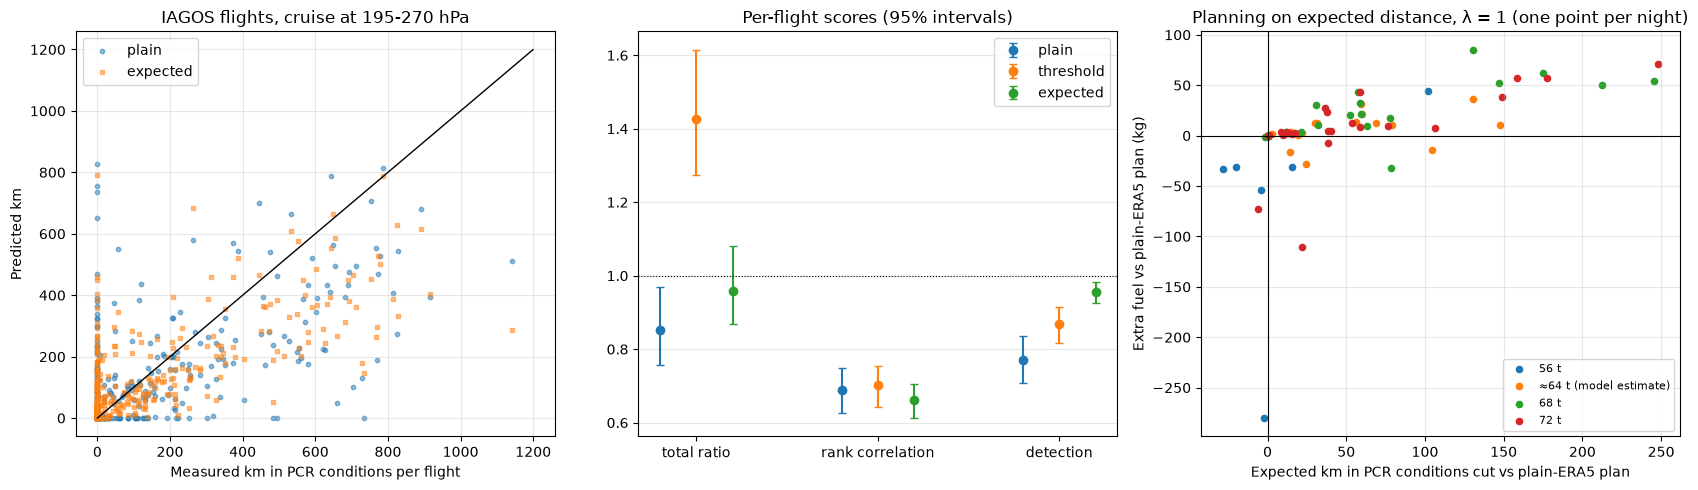

In [7]:
LABEL = {"light_56t": "56 t", "model_default": "≈64 t (model estimate)", "heavy_68t": "68 t", "very_heavy_72t": "72 t"}
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ax = axes[0]
lim = max(per["measured"].max(), per[["plain", "expected"]].max().max()) * 1.05
for m, mk in [("plain", "o"), ("expected", "s")]:
    ax.scatter(per["measured"], per[m], s=10, alpha=0.5, marker=mk, label=m)
ax.plot([0, lim], [0, lim], color="k", lw=1)
ax.set_xlabel("Measured km in PCR conditions per flight")
ax.set_ylabel("Predicted km")
ax.set_title("IAGOS flights, cruise at 195-270 hPa")
ax.legend()
ax.grid(alpha=0.3)

ax = axes[1]
names = {"total_ratio": "total ratio", "spearman": "rank correlation", "detection": "detection"}
x = np.arange(len(names))
for n, (_, r) in enumerate(fs.iterrows()):
    y = np.array([r[k] for k in names])
    err = np.vstack([y - np.array([r[k + "_lo"] for k in names]), np.array([r[k + "_hi"] for k in names]) - y])
    ax.errorbar(x + (n - 1) * 0.2, y, yerr=err, fmt="o", capsize=3, label=r["method"])
ax.axhline(1.0, color="k", lw=0.8, ls=":")
ax.set_xticks(x)
ax.set_xticklabels(list(names.values()))
ax.set_title("Per-flight scores (95% intervals)")
ax.legend()
ax.grid(alpha=0.3, axis="y")

ax = axes[2]
c1 = cmp_[cmp_["lambda"] == 1.0]
for mc in MASSES:
    d = c1[c1["mass_case"] == mc]
    ax.scatter(d["expected_km_cut"], d["extra_fuel_kg"], s=20, label=LABEL[mc])
ax.axhline(0, color="k", lw=0.8)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Expected km in PCR conditions cut vs plain-ERA5 plan")
ax.set_ylabel("Extra fuel vs plain-ERA5 plan (kg)")
ax.set_title("Planning on expected distance, λ = 1 (one point per night)")
ax.legend(loc="best", fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(fig_dir / "session14_planning_with_uncertainty.png", dpi=150, bbox_inches="tight")
plt.show()

## Results

### Setup

(A) 639 IAGOS flights with at least 50 km of cruise at 195–270 hPa: 510,104 km flown, of which 53,240 km (10.4%) were measured in persistent-contrail (PCR) conditions; 184 flights had at least 10 km. Thresholds and probabilities were fitted without each flight's month (out-of-month thresholds 0.91–0.93). (B) 864 plans: 24 nights × 4 masses × 3 λ × 3 methods (plain ERA5, threshold 0.91, expected distance from the probability), on FL330–FL390 with 2,000 ft steps and at most two level changes, each scored under all three views.

### Checks

- **The fits reproduce Session 13:** all-month threshold 0.91.
- **The planner's "plain" view equals its ordinary PCR evaluation exactly** (maximum difference 0).
- **The level rules hold:** 528 plans keep one level, 191 change once and 145 twice.
- **Re-timing:** 846 of 864 plans repeated after 2 or 3 plans; the other 18 were scored at their own timing like the rest.
- **Deviations from the rules fixed in advance:** none.

### Findings

#### 1. On real flights, the probability gets the total right, but no method predicts individual flights better than plain ERA5

Predicted against measured km in PCR conditions, per flight (95% intervals from resampling flights):

| Method | Total predicted / measured | Mean absolute error per flight (km) | Rank correlation across flights | Flights with ≥10 km measured also given ≥10 km |
|---|---|---|---|---|
| plain ERA5 | 0.85 [0.76–0.97] | 60 [50–70] | 0.69 [0.63–0.75] | 0.77 [0.71–0.84] |
| threshold (≈0.91) | 1.43 [1.28–1.62] | 66 [55–77] | 0.70 [0.64–0.76] | 0.87 [0.82–0.92] |
| expected (probability) | 0.96 [0.87–1.08] | 61 [53–70] | 0.66 [0.61–0.71] | 0.96 [0.93–0.98] |

- **The probability is right on average.** Its total ratio is 0.96, with an interval that includes 1, while plain ERA5 misses 15% of the contrail-forming distance and the threshold overstates it by 43%. That overstatement is the cost of choosing the threshold for the best yes/no score.
- **For a single flight, none of the three is more accurate.** The mean error per flight (60–66 km) and the rank correlation (0.66–0.70) have overlapping intervals. Session 13's better point-by-point scores do not turn into better per-flight distances.
- **The probability rarely misses a contrail-prone flight, but flags many clean ones.** It gave less than 1 km to only 2 of the 184 flights with at least 10 km measured (plain ERA5: 38; threshold: 23). In return it gave at least 10 km to 149 flights where less than 1 km was measured (plain: 50; threshold: 71). An expected distance spreads small amounts over every flight, so its detection score is easy to win; the error and correlation columns are the fairer test.

#### 2. Planning on the expected distance changes most heavy-aircraft routes when contrails carry real weight

Expected-distance plan against plain-ERA5 plan, 24 nights per row; medians [max]:

| Mass | λ | Plans that differ | Plain plan: expected km left | Expected km cut | Extra fuel (kg) |
|---|---|---|---|---|---|
| 56 t | 0.1 / 1 / 10 | 0 / 6 / 8 | 13 / 13 / 13 | 0 [0] / 0 [102] / 0 [139] | 0 [0] / 0 [44] / 0 [499] |
| ≈64 t | 0.1 / 1 / 10 | 4 / 18 / 21 | 102 / 48 / 48 | 0 [145] / 21 [148] / 33 [151] | 0 [10] / 2 [36] / 22 [400] |
| 68 t | 0.1 / 1 / 10 | 5 / 17 / 23 | 105 / 77 / 77 | 0 [59] / 42 [245] / 61 [250] | 0 [1] / 10 [85] / 52 [360] |
| 72 t | 0.1 / 1 / 10 | 9 / 23 / 24 | 176 / 161 / 153 | 0 [127] / 38 [248] / 94 [250] | 0 [8] / 5 [71] / 58 [513] |

- **Most heavy-aircraft plans change.** 158 of 288 plans differ from the plain-ERA5 plan, mostly for 64–72 t aircraft at λ = 1 and 10 (17–24 of 24 nights). At λ = 0.1, contrails are worth too little for the plan to change on most nights.
- **Plain ERA5's "clean" routes often aren't.** In 189 of 288 cases the plain-ERA5 plan has no PCR distance by its own measure but more than 5 km by the probability's.
- **Cuts are moderate and cheap for heavier aircraft.** Planning on the expected distance cuts a median 21–94 km of expected contrail-forming flight at λ = 1–10, for a median 2–58 kg of extra fuel (at most 513 kg). For a 56 t aircraft, which cruises above most of the moist air, there is little to gain (median 13 km left by the plain plan).
- **It can also save fuel.** On one night the expected-distance plan used about 280 kg less fuel than the plain plan (figure, right). Most likely, plain ERA5 marked a region as certainly contrail-forming and the plain plan detoured around it, while the probability judged the detour not worth its fuel (not checked case by case).
- **The threshold plan leaves almost as much expected distance as the plain plan** (medians 0–15 km less). Its plans differ from the expected-distance plans almost as often (154 of 288).

### What this means for the project

- **The probability is most useful as an average-case tool.** Over many flights it gets the contrail-forming distance right (finding 1), so plans built on it cut that distance on average for little fuel (finding 2). For any one flight it is no better than plain ERA5, so the cut is reliable for a fleet or a season, not for a single route on a single night. This matches the risk-based view in the related work (Platt et al., 2024; Borella et al., 2026).
- **The simple threshold is right for detecting supersaturated air at a point,** but wrong for totals (43% too much) and adds little to planning. For deciding routes, the probability is the better of the two corrections.

### Limitations

- The alternative routes cannot be checked against measurements; only the flown level is measured. Finding 2 relies on the probability being right on average, which finding 1 supports for totals but not for single flights.
- Plans are the planner's estimates, not re-flown through the full pipeline (Sessions 9 and 11 found those estimates within about 70 km of contrail distance).
- The probability was fitted at 195–270 hPa on one region and year (four IAGOS aircraft), and the planner used FL330–FL390 to stay inside that range.
- ERA5 is a reanalysis, not a forecast; with forecasts both the inputs and the probability would be less reliable.
- Seasonal differences in ERA5's errors (Session 13) are not modelled: one probability model and one threshold serve the whole year.